# Chapitre 9 - Cours 3 : Optimiser l'attention, le cache KV et les noyaux

L'attention est la troisième source de coût d'un transformer (après la taille et le
decode séquentiel) : chaque nouveau token doit « regarder » tous les précédents, ce qui
impose de garder leurs clés et valeurs en mémoire. Ce notebook couvre, dans la section
*Model Optimization* du livre :

- *Attention mechanism optimization* : le cache KV, sa taille (encadré *Calculating the KV
  Cache Size*), la refonte du mécanisme (*Redesigning the attention mechanism* : attention
  locale, multi-query, grouped-query, cross-layer), la gestion du cache (*Optimizing the KV
  cache size* : PagedAttention, quantification du cache) ;
- *Writing kernels for attention computation* et *Kernels and compilers* : FlashAttention,
  fusion d'opérateurs, tuilage, compilateurs, étude de cas PyTorch.

**Plan.** 1. Le cache KV ; 2. La taille du cache KV ; 3. Repenser l'attention : MQA, GQA,
fenêtre locale ; 4. Gérer le cache : PagedAttention ; 5. Noyaux : fusion, tuilage,
FlashAttention ; 6. Compilateurs ; Synthèse.

In [1]:
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from matplotlib.colors import ListedColormap

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, TransformerConfig, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, COLORS,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
GB = 1e9

## 1. Le cache KV (section *Attention mechanism optimization*)

Pour produire le token $x_{t+1}$, chaque couche d'attention a besoin des clés $k_i$ et des
valeurs $v_i$ de **tous** les tokens précédents $x_1, \dots, x_t$. Or ces vecteurs ne
changent pas d'un pas à l'autre (masque causal : un token ne voit jamais le futur). Au
lieu de les recalculer, on les **garde** : c'est le **cache KV**. À chaque pas, on ne
calcule $q, k, v$ que pour le dernier token, on ajoute $k_t, v_t$ au cache, et la requête
$q_t$ est comparée à toutes les clés du cache.

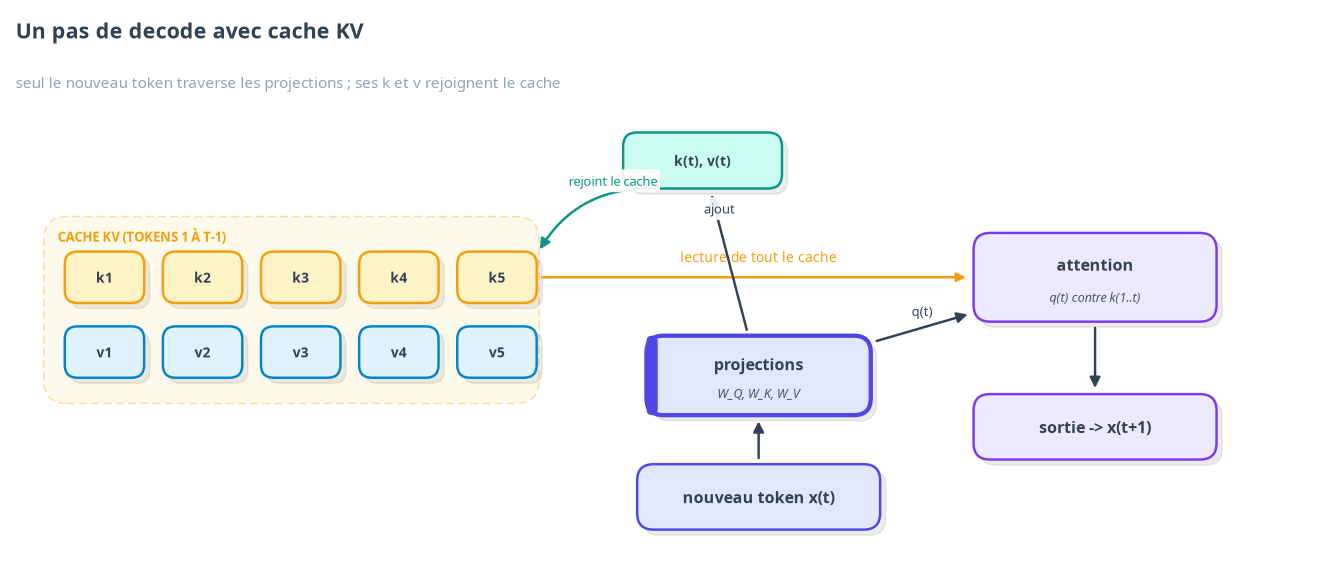

In [2]:
d = Diagram(14, 5.0, title="Un pas de decode avec cache KV",
            subtitle="seul le nouveau token traverse les projections ; ses k et v rejoignent le cache")
for i in range(5):
    d.box(f"k{i}", 1.0 + i * 1.05, 3.1, f"k{i + 1}", color=AMBER, w=0.85, h=0.55, fontsize=9)
    d.box(f"v{i}", 1.0 + i * 1.05, 2.3, f"v{i + 1}", color=SKY, w=0.85, h=0.55, fontsize=9)
d.group(0.35, 1.75, 5.65, 3.75, "cache KV (tokens 1 à t-1)", color=AMBER)
d.box("x", 8.0, 0.75, "nouveau token x(t)", color=INDIGO, w=2.6, h=0.7)
d.box("proj", 8.0, 2.05, "projections", sub="W_Q, W_K, W_V", color=INDIGO, kind="model", w=2.4, h=0.85)
d.box("kt", 7.4, 4.35, "k(t), v(t)", color=TEAL, w=1.7, h=0.6, fontsize=9)
d.box("att", 11.6, 3.1, "attention", sub="q(t) contre k(1..t)", color=VIOLET, w=2.6, h=0.95)
d.box("o", 11.6, 1.5, "sortie -> x(t+1)", color=VIOLET, w=2.6, h=0.7)
d.arrow("x", "proj"); d.arrow("proj", "kt", "ajout", label_pos=0.75); d.arrow("proj", "att", "q(t)")
d.arrow("kt", "k4", "rejoint le cache", rad=0.3, color=TEAL, label_offset=(0.3, 0.25))
d.line([(5.65, 3.1), (10.25, 3.1)], color=AMBER, style="solid", lw=1.6)
d.note(8.0, 3.32, "lecture de tout le cache", color=AMBER, fontsize=9, style="normal")
d.arrow("att", "o")
d.show()

Le cache ne sert qu'à l'**inférence** : à l'entraînement, toute la séquence est connue et
traitée d'un coup (encadré du livre). **Mesure** sur Qwen2.5-0.5B : on génère 128 tokens
après un prompt de 512 tokens, avec notre boucle gloutonne, en recalculant tout le préfixe
à chaque pas (sans cache) ou en réutilisant le cache.

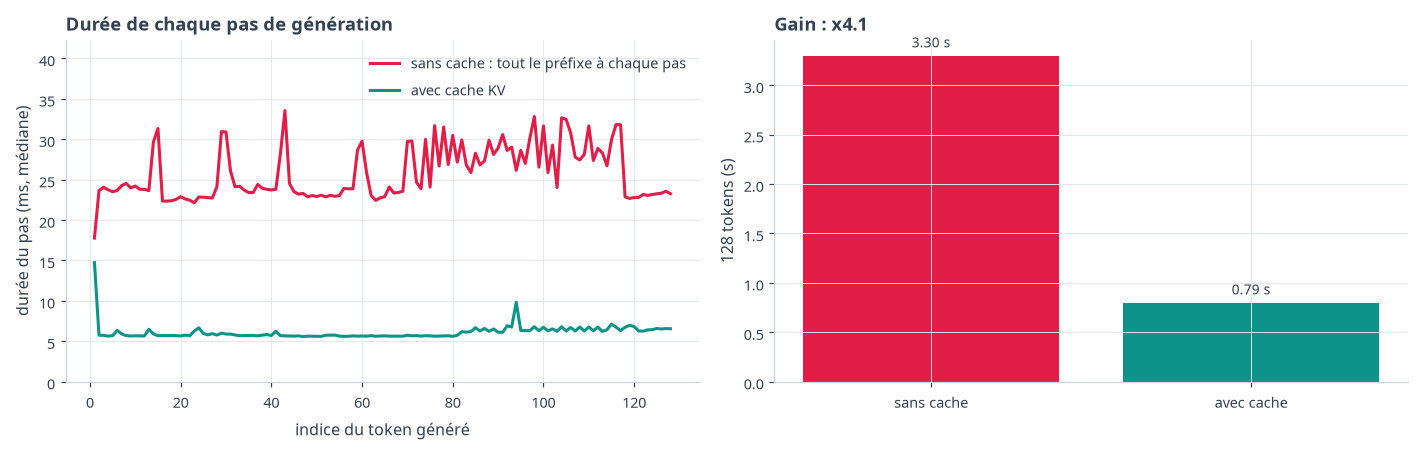

mêmes tokens avec et sans cache : True


In [3]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)


def cache_vs_nocache():
    ids = inf.random_ids(1, 512, seed=3)[0].tolist()
    inf.greedy_generate(model, ids, 4); inf.greedy_generate(model, ids, 4, use_cache=False)
    with_c = [inf.greedy_generate(model, ids, 128) for _ in range(3)]
    without = [inf.greedy_generate(model, ids, 128, use_cache=False) for _ in range(2)]
    return with_c, without


with_c, without = inf.retry_oom(cache_vs_nocache)
gaps_c = np.median([np.diff([0] + r.times) for r in with_c], axis=0) * 1e3
gaps_n = np.median([np.diff([0] + r.times) for r in without], axis=0) * 1e3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(np.arange(1, 129), gaps_n, color=ROSE, label="sans cache : tout le préfixe à chaque pas")
ax.plot(np.arange(1, 129), gaps_c, color=TEAL, label="avec cache KV")
ax.set_ylim(0, np.percentile(gaps_n, 98) * 1.3)
ax.set_xlabel("indice du token généré"); ax.set_ylabel("durée du pas (ms, médiane)")
ax.set_title("Durée de chaque pas de génération"); ax.legend()
ax = axes[1]
tot = [np.median([r.seconds for r in without]), np.median([r.seconds for r in with_c])]
ax.bar(["sans cache", "avec cache"], tot, color=[ROSE, TEAL]); annotate_bars(ax, "{:.2f} s")
ax.set_ylabel("128 tokens (s)"); ax.set_title(f"Gain : x{tot[0] / tot[1]:.1f}")
plt.tight_layout(); plt.show()
print("mêmes tokens avec et sans cache :", with_c[0].tokens == without[0].tokens)

Sans cache, chaque pas est un prefill de plus de 500 tokens, de plus en plus long ; avec le
cache, chaque pas ne traite qu'un token. Pour un petit modèle et 640 tokens au plus, le
prefill reste rapide (cours 1) et le gain est de quelques fois ; il devient énorme sur des
contextes de milliers de tokens, car le travail sans cache croît **quadratiquement** avec
la longueur (note 22 du livre : $O(n^2)$ calculs d'attention au total), alors que la taille
du cache croît **linéairement**.

> **À retenir.** Le cache KV échange du calcul contre de la mémoire : il évite de
> recalculer les clés et valeurs du passé, au prix de les stocker... ce qui devient le
> problème suivant.

## 2. La taille du cache KV (encadré *Calculating the KV Cache Size*)

Sans optimisation (attention multi-têtes classique), il faut stocker, pour chaque couche
et chaque token, une clé et une valeur de dimension $H$ (la dimension du modèle) :
$$\text{mémoire KV} = 2 \times B \times S \times L \times H \times M,$$
avec $B$ la taille du lot, $S$ la longueur de séquence, $L$ le nombre de couches et $M$ les
octets par nombre. Avec $h_{kv}$ têtes clés-valeurs de dimension $d_h$ (GQA, section 3),
$H$ est remplacé par $h_{kv}\, d_h$. L'exemple du livre, Llama 2-13B :

In [4]:
book = inf.kv_cache_bytes_book(batch=32, seq_len=2048, n_layers=40, d_model=5120, bytes_per=2)
print(f"Llama 2-13B, B=32, S=2048, fp16 : {book / GB:.1f} Go de cache KV"
      f" (poids : {count_params_config(KNOWN_CONFIGS['Llama 2-13B']) * 2 / GB:.0f} Go)")

Llama 2-13B, B=32, S=2048, fp16 : 53.7 Go de cache KV (poids : 26 Go)


54 Go : plus du double des poids. Vérifions la formule sur un vrai cache Hugging Face :
on remplit le cache de Qwen2.5-0.5B (24 couches, 2 têtes KV de dimension 64) et on
additionne la taille de ses tenseurs.

In [5]:
cfg05 = KNOWN_CONFIGS["Qwen2.5-0.5B"]
rows = []
with torch.no_grad():
    for S in [128, 512, 2048]:
        cache = model(inf.random_ids(2, S), use_cache=True, logits_to_keep=1).past_key_values
        real = sum(l.keys.numel() * l.keys.element_size() + l.values.numel() * l.values.element_size()
                   for l in cache.layers)
        rows.append({"S": S, "B": 2, "mesuré (Mo)": real / 1e6, "formule (Mo)": kv_cache_bytes(cfg05, S, batch=2) / 1e6})
        del cache
pd.DataFrame(rows)

,S,B,mesuré (Mo),formule (Mo)
0,128,2,3.146,3.146
1,512,2,12.583,12.583
2,2048,2,50.332,50.332


Accord exact. Traçons maintenant la mémoire du cache **par séquence** en fonction du
contexte pour quelques modèles, et comparons-la à celle des poids.

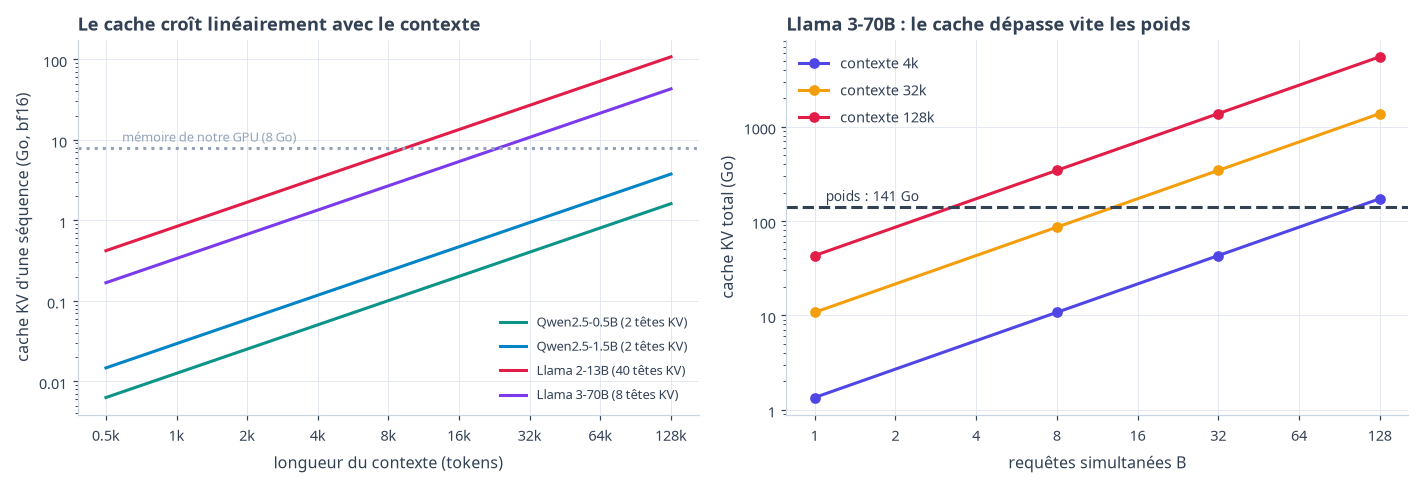

In [6]:
S = np.logspace(np.log10(512), np.log10(131072), 60)
models_ = ["Qwen2.5-0.5B", "Qwen2.5-1.5B", "Llama 2-13B", "Llama 3-70B"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for k, c in zip(models_, [TEAL, SKY, ROSE, VIOLET]):
    cfg = KNOWN_CONFIGS[k]
    ax.plot(S, kv_cache_bytes(cfg, S) / GB, color=c, label=f"{k} ({cfg.kv_heads} têtes KV)")
ax.axhline(8, color=GRAY, ls=":"); ax.text(600, 9.5, "mémoire de notre GPU (8 Go)", color=GRAY, fontsize=8.5)
ax.set_xscale("log", base=2); ax.set_yscale("log"); plain_log_axis(ax, "x", fmt=lambda v: f"{v / 1024:g}k")
plain_log_axis(ax, "y")
ax.set_xlabel("longueur du contexte (tokens)"); ax.set_ylabel("cache KV d'une séquence (Go, bf16)")
ax.set_title("Le cache croît linéairement avec le contexte"); ax.legend(fontsize=8.5)
ax = axes[1]
cfg = KNOWN_CONFIGS["Llama 3-70B"]
w = count_params_config(cfg) * 2 / GB
Bs = np.array([1, 8, 32, 128])
for S_, c in zip([4096, 32768, 131072], [INDIGO, AMBER, ROSE]):
    ax.plot(Bs, kv_cache_bytes(cfg, S_, batch=Bs) / GB, "o-", color=c, label=f"contexte {S_ // 1024}k")
ax.axhline(w, color=SLATE, ls="--"); ax.text(1.1, w * 1.15, f"poids : {w:.0f} Go", color=SLATE, fontsize=9)
ax.set_xscale("log", base=2); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("requêtes simultanées B"); ax.set_ylabel("cache KV total (Go)")
ax.set_title("Llama 3-70B : le cache dépasse vite les poids"); ax.legend()
plt.tight_layout(); plt.show()

Le cache KV est **le** facteur limitant des longs contextes et des gros lots : à 32
requêtes de 32k tokens, Llama 3-70B (pourtant doté de GQA) demande plus de mémoire pour
son cache que pour ses poids. Le livre cite un article de Google (Pope et al., 2022) : pour
un modèle de plus de 500 milliards de paramètres en attention multi-têtes, lot de 512 et
contexte 2048, le cache atteint 3 To, trois fois les poids. Lire ce cache à chaque pas
coûte aussi de la **bande passante** : il s'ajoute aux poids dans le calcul de la MBU.

> **À retenir.** Cache KV $= 2 \cdot B \cdot S \cdot L \cdot h_{kv} d_h \cdot M$ :
> linéaire en lot et en contexte. Il limite le nombre de requêtes simultanées, donc le
> débit ; tous les leviers de la suite visent l'un de ces facteurs.

## 3. Repenser l'attention : MQA, GQA, fenêtre locale (section *Redesigning the attention mechanism*)

Ces techniques changent l'architecture : elles s'appliquent à l'entraînement (ou au
finetuning), pas après coup.

- **Multi-query attention** (MQA, Shazeer, 2019) : toutes les têtes de requêtes partagent
  **une seule** paire clé-valeur ; cache divisé par $h$.
- **Grouped-query attention** (GQA, Ainslie et al., 2023) : les $h$ têtes de requêtes sont
  réparties en $h_{kv}$ groupes qui partagent chacun une paire clé-valeur ; cache divisé
  par $h / h_{kv}$. MHA ($h_{kv} = h$) et MQA ($h_{kv} = 1$) en sont les cas extrêmes.
- **Cross-layer attention** (Brandon et al., 2024) : des couches adjacentes partagent
  leurs clés et valeurs (trois couches qui partagent : cache divisé par 3).
- **Attention locale à fenêtre** (Beltagy et al., 2020) : chaque token ne regarde que les
  $w$ derniers ; le cache plafonne à $w$ tokens. On l'entrelace souvent avec des couches
  d'attention globale.

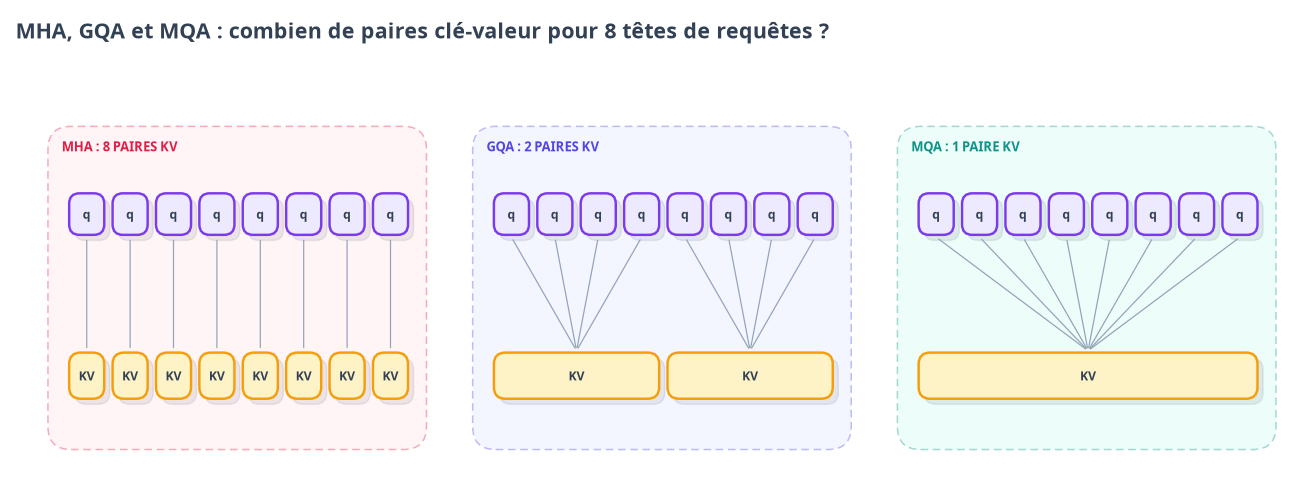

In [7]:
d = Diagram(14, 4.4, title="MHA, GQA et MQA : combien de paires clé-valeur pour 8 têtes de requêtes ?")
for g, (name, n_kv, x0) in enumerate([("MHA : 8 paires KV", 8, 0.4), ("GQA : 2 paires KV", 2, 5.0),
                                      ("MQA : 1 paire KV", 1, 9.6)]):
    d.group(x0, 0.2, x0 + 4.1, 3.7, name, color=[ROSE, INDIGO, TEAL][g])
    for i in range(8):
        d.box(f"q{g}{i}", x0 + 0.42 + i * 0.47, 2.75, "q", color=VIOLET, w=0.38, h=0.45, fontsize=8)
    span = 8 // n_kv
    for j in range(n_kv):
        xc = x0 + 0.42 + (j * span + (span - 1) / 2) * 0.47
        wk = max(0.38, span * 0.47 - 0.09)
        d.box(f"kv{g}{j}", xc, 1.0, "KV", color=AMBER, w=wk, h=0.5, fontsize=8)
        for i in range(j * span, (j + 1) * span):
            d.line([(x0 + 0.42 + i * 0.47, 2.5), (xc, 1.27)], color=GRAY, style="solid", lw=0.8, arrow=False)
d.show()

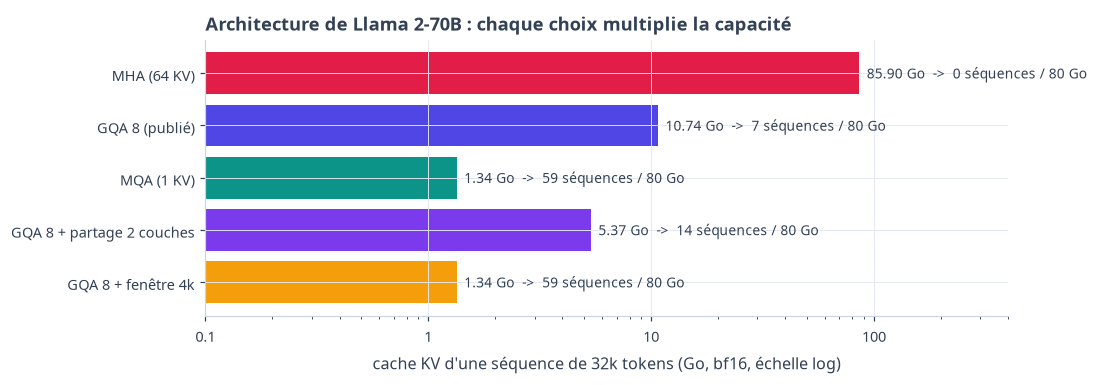

In [8]:
base70 = KNOWN_CONFIGS["Llama 2-70B"]  # 64 têtes de requêtes, 8 têtes KV dans la version publiée
variants = {"MHA (64 KV)": dict(n_kv_heads=64), "GQA 8 (publié)": dict(n_kv_heads=8),
            "MQA (1 KV)": dict(n_kv_heads=1), "GQA 8 + partage 2 couches": dict(n_kv_heads=8, layer_share=2),
            "GQA 8 + fenêtre 4k": dict(n_kv_heads=8, window=4096)}
S_ctx = 32768
rows = []
for name, kw in variants.items():
    b = inf.kv_cache_bytes_gqa(1, S_ctx, base70.n_layers, kw["n_kv_heads"], base70.head_dim,
                               window=kw.get("window"), layer_share=kw.get("layer_share", 1))
    rows.append({"variante": name, "cache par séquence (Go)": b / GB,
                 "séquences dans 80 Go libres": int(80 * GB // b)})
kvv = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(kvv["variante"], kvv["cache par séquence (Go)"], color=[ROSE, INDIGO, TEAL, VIOLET, AMBER])
for i, (v, n_) in enumerate(zip(kvv["cache par séquence (Go)"], kvv["séquences dans 80 Go libres"])):
    ax.text(v * 1.08, i, f"{v:.2f} Go  ->  {n_} séquences / 80 Go", va="center", fontsize=9)
ax.set_xscale("log"); plain_log_axis(ax, "x"); ax.invert_yaxis(); ax.set_xlim(0.1, 400)
ax.set_xlabel("cache KV d'une séquence de 32k tokens (Go, bf16, échelle log)")
ax.set_title("Architecture de Llama 2-70B : chaque choix multiplie la capacité")
plt.tight_layout(); plt.show()

Passer de MHA à GQA-8 divise le cache par 8 ; la fenêtre locale le plafonne
indépendamment du contexte. Character.AI rapporte (livre) des conversations de 180
messages en moyenne : en combinant MQA, attention locale entrelacée avec quelques couches
globales et partage entre couches, ils réduisent le cache de plus de 20 fois, au point que
la mémoire ne limite plus la taille de leurs lots. Petit calcul de vraisemblance :

In [9]:
h, L_ = 32, 24  # hypothèses : 32 têtes, 24 couches
mqa = h  # facteur de MQA par rapport à MHA
# 1 couche globale sur 6, les 5 autres locales (fenêtre 1024) ; partage KV par 2 couches ; contexte 16k
S_, w_ = 16384, 1024
frac_tokens = (1 / 6) * 1 + (5 / 6) * w_ / S_
total_factor = mqa / frac_tokens * 2
print(f"MQA : /{mqa} ; local/global : /{1 / frac_tokens:.1f} ; partage entre couches : /2"
      f" -> réduction totale ~ /{total_factor:.0f} par rapport à MHA")

MQA : /32 ; local/global : /4.6 ; partage entre couches : /2 -> réduction totale ~ /293 par rapport à MHA


Même sans MQA, les deux autres mécanismes donnent déjà un facteur de l'ordre de 10 sur
ces hypothèses ; avec MQA, la réduction est bien supérieure au facteur 20 annoncé (qui se
compare sans doute à une base déjà optimisée).

**La fenêtre locale en image.** Masque d'attention causal complet contre fenêtre de
$w = 4$ tokens :

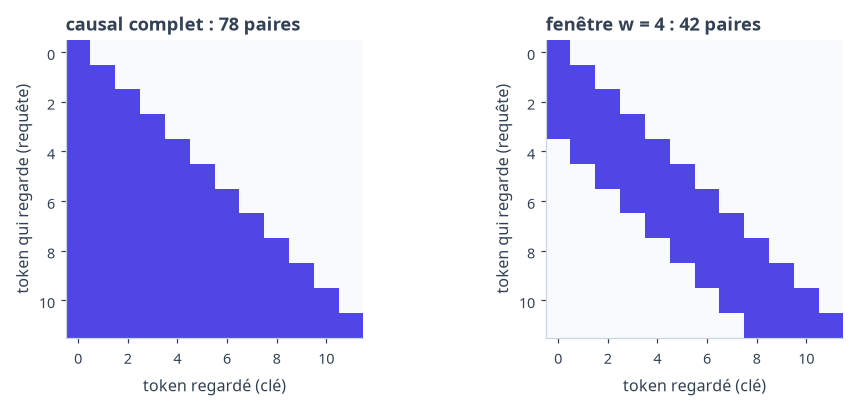

In [10]:
T_ = 12
full = np.tril(np.ones((T_, T_)))
win = np.tril(np.ones((T_, T_))) * (np.arange(T_)[:, None] - np.arange(T_)[None, :] < 4)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M_, t in zip(axes, [full, win], [f"causal complet : {int(full.sum())} paires",
                                         f"fenêtre w = 4 : {int(win.sum())} paires"]):
    ax.imshow(M_, cmap=ListedColormap(["#F8FAFC", INDIGO])); ax.set_title(t)
    ax.set_xlabel("token regardé (clé)"); ax.set_ylabel("token qui regarde (requête)"); ax.grid(False)
plt.tight_layout(); plt.show()

> **À retenir.** MQA / GQA réduisent le nombre de paires clé-valeur, le partage entre
> couches réduit le nombre de couches à stocker, la fenêtre locale borne le nombre de
> tokens. Ces choix se font à l'entraînement : la plupart des modèles récents (Llama 3,
> Qwen2.5, Mistral) utilisent GQA.